In [2]:
import pandas as pd

df = pd.read_csv("annotated_pilot.csv", encoding="utf-8-sig")
df.columns = [c.strip() for c in df.columns]
df["domain"] = df["domain"].astype(str).str.strip().str.lower()
yes = lambda s: s.astype(str).str.strip().str.lower().eq("yes")

df["has_role"] = yes(df["role"].astype(str))
df["narr"] = yes(df["narrative"])
df["ad"] = yes(df["ad_repost?"])



print(df.groupby("domain").agg(n=("message_id", "size"),
                               narrative_yes=("narr", "mean"),
                               has_role=("has_role", "mean"),
                               ad_yes=("ad", "mean")).round(2))
print(df.groupby(["domain", "channel"]).size())


           n  narrative_yes  has_role  ad_yes
domain                                       
crypto    48           0.02      0.15    0.46
migrants  36           1.00      1.00    0.19
war       50           0.44      0.96    0.06
domain    channel                 
crypto    Benefactor0101               7
          CRYPTO_jokker               15
          cryp2day                    11
          the_signal_24               15
migrants  Graham_Hodsdon10             7
          PatriotsAnonymous            2
          SlovjanskaInformacja        16
          StandTogetherSouthEast       2
          Visegrad_24                  2
          WaslIslamicNews              2
          WhiteLads                    1
          jfksecrets2025               4
war       KyivIndependent_official    10
          MFARussia                   10
          llordofwar                  10
          ourwarstoday                10
          worldnewschannel3           10
dtype: int64


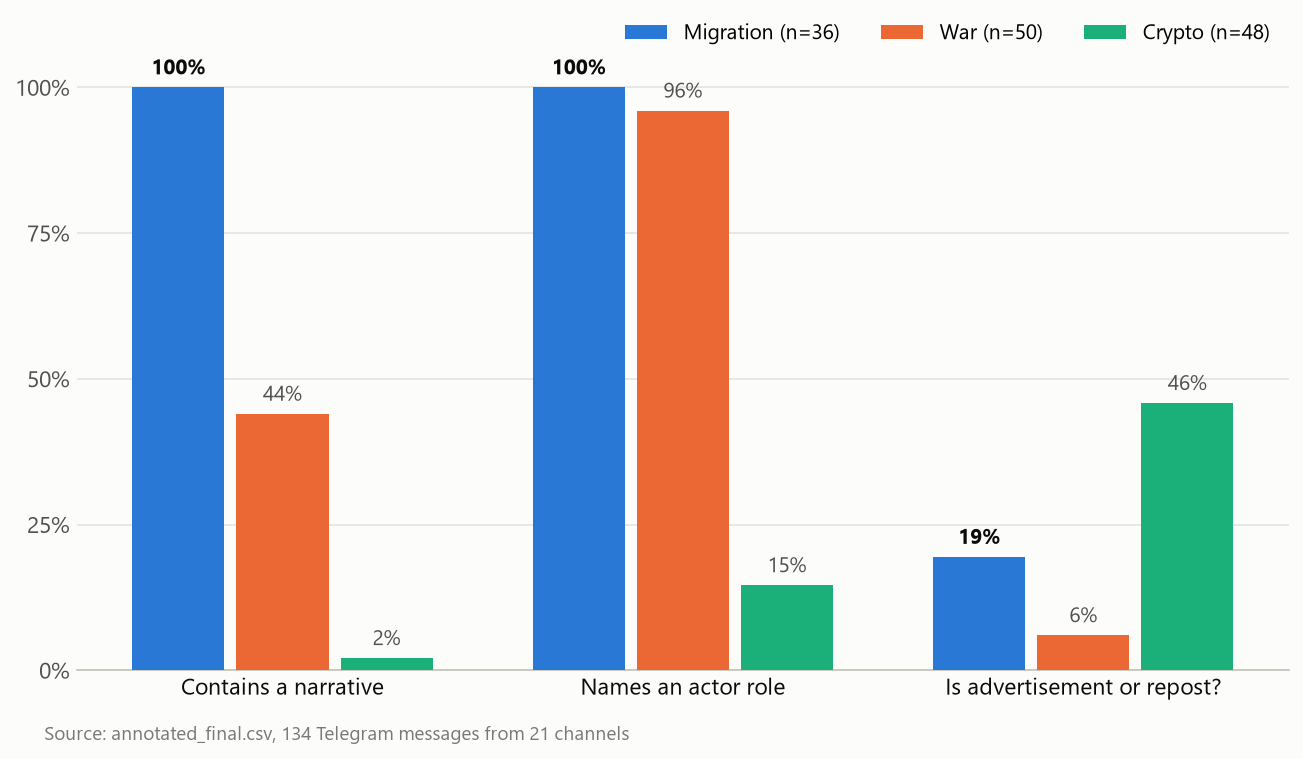

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

metrics = {"narr": "Contains a narrative", "has_role": "Names an actor role", "ad": "Is advertisement or repost?"}
topics = {"migrants": "Migration", "war": "War", "crypto": "Crypto"}   
colors = {"migrants": "#2a78d6", "war": "#eb6834", "crypto": "#1baf7a"}

share = df.groupby("domain")[list(metrics)].mean() * 100
counts = df["domain"].value_counts()

plt.rcParams.update({"font.family": "Segoe UI", "font.size": 11})
fig, ax = plt.subplots(figsize=(9, 5.2), dpi=150)
fig.patch.set_facecolor("#fcfcfb"); ax.set_facecolor("#fcfcfb")

x = np.arange(len(metrics))
width = 0.26
for i, (dom, name) in enumerate(topics.items()):
    vals = share.loc[dom, list(metrics)].values
    bars = ax.bar(x + (i - 1) * width, vals, width - 0.03, color=colors[dom],
                  label=f"{name} (n={counts[dom]})", zorder=3)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:.0f}%", ha="center", va="bottom",
                fontsize=10, color="#0b0b0b" if dom == "migrants" else "#52514e",
                fontweight="bold" if dom == "migrants" else "normal")

ax.set_xticks(x, metrics.values(), color="#0b0b0b")
ax.set_ylim(0, 112)
ax.set_yticks(range(0, 101, 25), [f"{t}%" for t in range(0, 101, 25)], color="#52514e")
ax.tick_params(length=0)
ax.grid(axis="y", color="#e4e3df", linewidth=0.8, zorder=0)
for s in ax.spines.values():
    s.set_visible(False)
# Share of annotated messages with each property, by domain
ax.spines["bottom"].set_visible(True); ax.spines["bottom"].set_color("#c3c2b7")
ax.legend(frameon=False, loc="upper right", ncol=3, bbox_to_anchor=(1, 1.02), fontsize=10)
fig.text(0.06, 0.01, f"Source: annotated_final.csv, {len(df)} Telegram messages from 21 channels",
         fontsize=9, color="#7a7974")
fig.tight_layout(rect=(0.02, 0.03, 1, 0.97))
fig.savefig("topic_choice1.png", facecolor=fig.get_facecolor(), bbox_inches="tight")
plt.show()
